# Exp 4 — Hardware-native quantum reservoirs: EuroHPC feasibility study

**Question.** Can the workflow of this repository,

> **native reservoir → resource metrics → expressivity diagnostics (ORS, $R_\mathrm{eff}$) → task performance**,

be built *natively* for three quantum computers with different hardware modalities?

| Machine | Technology | Native reservoir |
|---|---|---|
| **Euro-Q-Exa** (LRZ) | IQM superconducting qubits, square lattice | PRX + CZ layers on 6 qubits of the IQM Crystal-54 chip map |
| **Piast-Q** (PCSS) | AQT trapped ions, all-to-all | R + RZ + RXX (Mølmer–Sørensen) layers on 6 ions |
| **Lucy** (CEA/TGCC) | Quandela photonics | 3 single photons in 12 modes; the data set 6 phase shifters between two random interferometers; photon counting (Perceval) |

The tasks are Exp3's: **LiH excitation energies** (QELM) and **ems_3 electricity demand** (QRC). Everything is simulated, hardware execution is the next step.

**Key results** (simulation, 6 encoding sites per machine)

1. **Native and accepted.** Every circuit uses only native operations, with 0 SWAP operations.
2. **Expressivity is tunable.** One native parameter takes each design up to the level of a maximally random (Haar) circuit:
   - Euro-Q-Exa at $L = 16$ cycles;
   - Piast-Q close to it at full connectivity ($\rho = 1$);
   - Lucy at full mesh depth $D = 12$.
3. **Task: Predicting excited energies of LiH** All three machines reach chemical accuracy (1.6 mHa).
   - Test error 0.36 mHa on Euro-Q-Exa and Piast-Q, 0.19 mHa on Lucy.
   - Lucy beats the best classical fit (0.47 mHa) and Exp3's full-state reservoirs (0.34 mHa).
   - About 40 training geometries are needed (30 on Lucy).
4. **Energy forecasting.** The hardware-executable protocol reaches R² ≈ 0.51 on every machine.
   - This is above linear forecasting (0.445) and on par with the classical quadratic model on the same two inputs (0.49).
   - The reservoir choice does not matter here, so the cheapest circuit is the right one for hardware.
5. **15 minutes of QPU time, inference only.** With indicative shot rates, the LiH error on 20 test geometries would be:
   - Lucy ≈ 0.8 mHa (within chemical accuracy);
   - Euro-Q-Exa ≈ 3 mHa (R² 0.98);
   - Piast-Q: shot-limited, with R² ≈ 0.78 at the conservative rate assumed here.

In [1]:
import json, subprocess, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
import perceval as pcvl

from native_reservoirs import hardware_specs as hs, plotting as pl, report as rp, tasks
from native_reservoirs.experiment import (Exp4Config, run_all, make_reservoir, get_data, export_vendor_circuits,
                                          classical_baselines, lih_inference_budget, qrc_inference_budget,
                                          vendor_noise_crosscheck)
from native_reservoirs.aqt_iontrap import AQTIonTrapReservoir
from native_reservoirs.adapters import GateWindowFeatures, weights_to_angles

FORCE = False                                   # True → recompute everything instead of loading the cache
cfg = Exp4Config(n_jobs=-1)
OUT, TAB = cfg.path, cfg.path / "tables"; TAB.mkdir(parents=True, exist_ok=True)
VENDOR_PY = hs.REPO_ROOT.parent / ".venv-vendor" / "bin" / "python"
REPRESENTATIVE = {"iqm": 8, "aqt": 1.0, "quandela": 12, "haar_qubit": "haar"}
show = lambda df: display(df.style.hide(axis="index"))
def cached(name, fn):
    path = OUT / f"{name}.csv"
    if FORCE or not path.exists():
        fn().to_csv(path, index=False)
    return pd.read_csv(path)

out = run_all(cfg, force=FORCE, verbose=False)                   # 170 reservoir instances + ORS (cached)
R, META = out["records"], out["metadata"]
S = pl.cell_summary(R, out["ors"])                               # mean ± standard error per (platform, level)
if FORCE or not (OUT / "baselines_lih.csv").exists():
    cb = classical_baselines(cfg); cb["lih"].to_csv(OUT / "baselines_lih.csv", index=False); cb["energy"].to_csv(OUT / "baselines_energy.csv", index=False)
BL, BE = pd.read_csv(OUT / "baselines_lih.csv"), pd.read_csv(OUT / "baselines_energy.csv")
d = get_data(cfg); _, te = tasks.lih_split_indices(); VAR = d["lih"]["y"][te].var(axis=0).mean()
pl.set_style()
print(f"config {cfg.hash()} | {len(R)} reservoir instances")

config 190308dce92c | 160 reservoir instances


## 1. The three native reservoirs

Each reservoir uses **only operations the machine executes natively**, on **its real connectivity**. Its complexity is set by one platform-native parameter.

- **Euro-Q-Exa (IQM).** Six neighbouring qubits of the IQM Crystal-54 chip, taken from IQM's SDK. One *cycle* is a random PRX rotation on every qubit followed by CZ gates on non-overlapping chip couplers. No qubit routing (SWAPs) is needed. Complexity: number of cycles $L$.
- **Piast-Q (AQT).** Six ions, any pair can interact. One *layer* is a random single-ion rotation followed by RXX gates on a random set of ion pairs; there are 4 layers. Complexity: the fraction $\rho$ of pairs that are entangled.
- **Lucy (Quandela).** Three photons enter 12 optical modes and pass a random interferometer, then 6 phase shifters that carry the data, then a second random interferometer. They are then counted.
  - *Why this design:* it follows the photonic reservoir paper (arXiv:2605.10471), which uses 2 photons. Few photons keep the coincidence rate high enough for the available QPU time.
  - *Random meshes:* they are sampled so that a full-depth mesh ($D=12$) is a uniformly random (Haar) interferometer.
  - *Features:* photon-number correlations $\langle n_i\rangle$, $\langle n_in_j\rangle$.
  - *Complexity:* mesh depth $D$.

A 6-qubit Haar-random unitary, the reference family of Exp1–3, is included for comparison. It is **not** native.

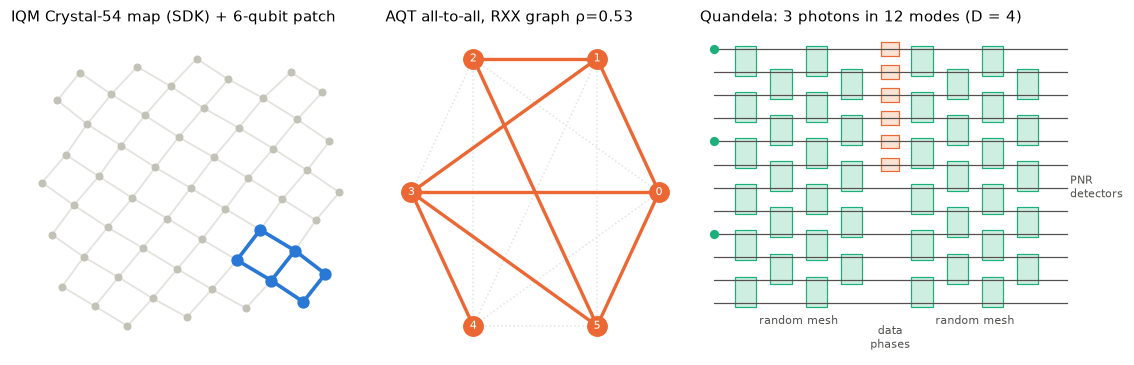

**Table A — native reservoir architectures**

platform,modality,native ops,topology,reservoir,encoding,measurement / features,complexity,simulated,hardware capacity
Euro-Q-Exa (IQM),"superconducting, gate-based","PRX(θ,φ), CZ","Crystal square lattice (SDK map, 54 q)",L cycles: PRX on all qubits + CZ on one edge-colour class of the patch,"LiH: PRX(θ_j, π/2); QRC: PRX(π/2, π/2−πu) per step",Z/X/Y settings; 1-local (LiH) and 1+2-local (QRC) Paulis,"L ∈ (1, 2, 4, 8, 16)",6-qubit patch,54 qubits (150 planned)
Piast-Q (AQT),"trapped ions, gate-based","R(θ,φ), RZ (virtual), RXX(θ≤π/2)",all-to-all (20 ions),4 layers: R+RZ on all ions + RXX on a random graph of density ρ,"LiH: R(θ_j, π/2); QRC: R(π/2, π/2−πu) per step",end-of-circuit Z/X/Y settings; same Pauli features,"ρ ∈ (0.25, 0.5, 0.75, 1.0)",6 ions,20 qubits
Lucy (Quandela),"photonic, linear optics","BS, PS (MZI mesh), single photons, photon counting",all-to-all universal interferometer (24 modes),"two Haar-dialled MZI meshes of depth D (U_pre, U_res) around the data phases; QRC: U_res after each of W=2 injections","6 data phase shifters θ_j ∈ [0, π] between the meshes","photon counting, post-selected on 3 photons; ⟨n_i⟩, ⟨n_i n_j⟩ (78)","D ∈ (1, 2, 4, 6, 12) + Haar",3 photons / 12 modes,"24 modes, 12 photons"


In [2]:
fig = pl.fig_architectures(make_reservoir("iqm", 4, 0, cfg), make_reservoir("aqt", 0.5, 0, cfg), make_reservoir("quandela", 4, 0, cfg)); plt.show()
TA = pl.table_architectures(cfg); pl.export_table(TA, "tableA_architectures", TAB)
display(Markdown("**Table A — native reservoir architectures**")); show(TA)

### The circuits

**LiH circuits.** Each drawing shows one bond length: the data first, then the reservoir, then measurement. The photonic circuit is decomposed into beam splitters (BS) and phase shifters (Φ), shown at depth $D=1$ for readability.

**Euro-Q-Exa (IQM), L = 4** — `R(θ, φ)` is IQM's native PRX gate

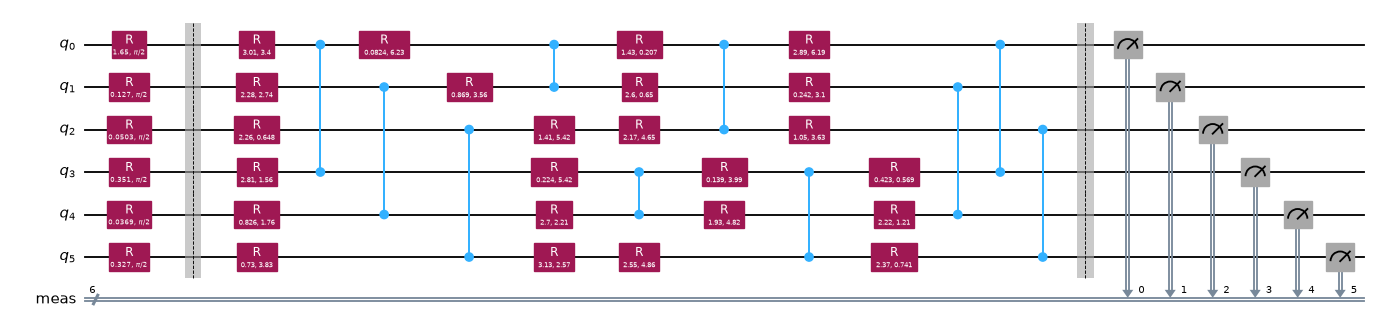

**Piast-Q (AQT), ρ = 0.5**

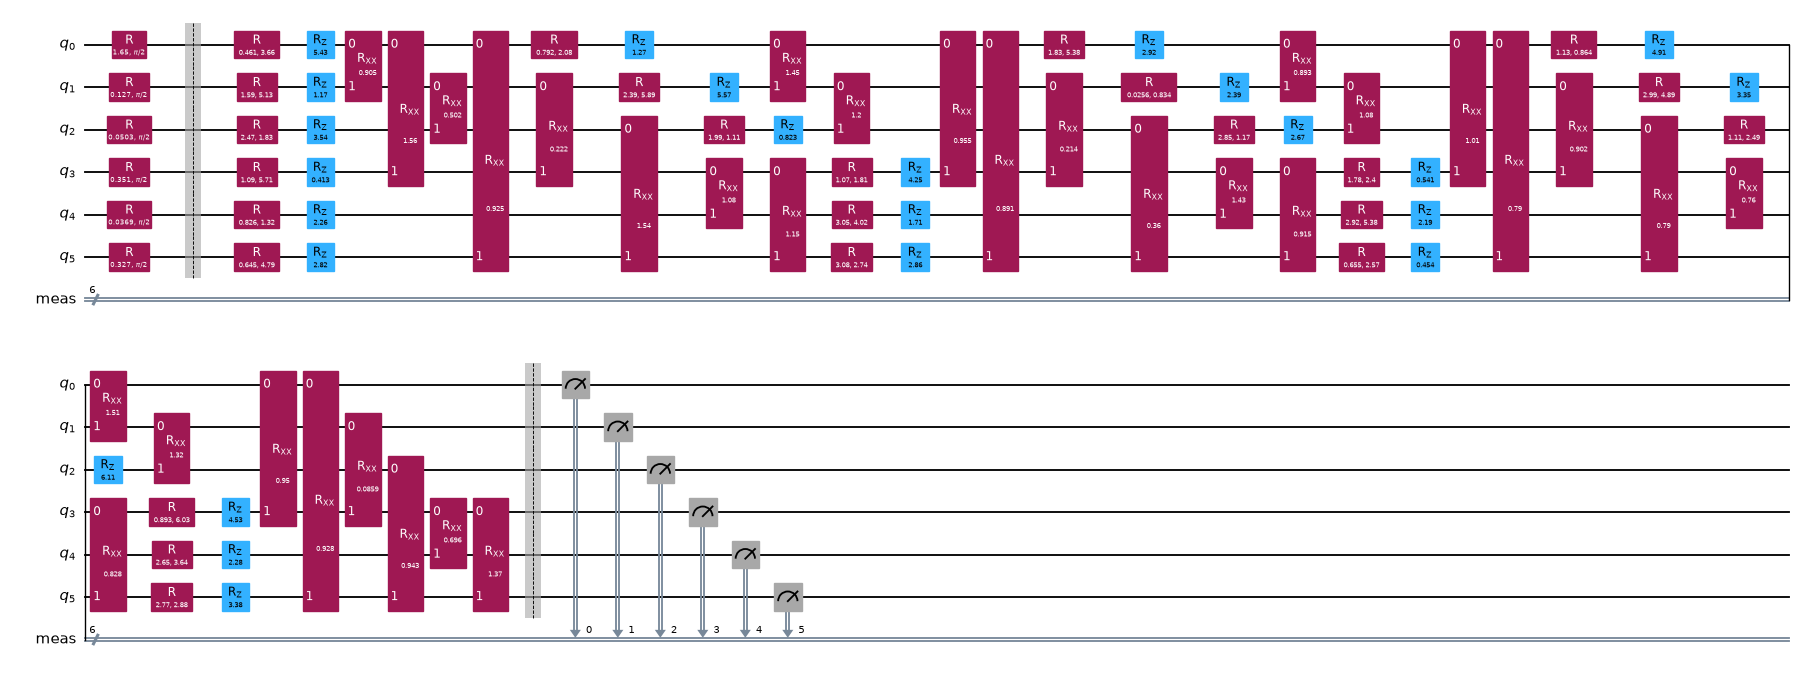

**Lucy (Quandela), D = 1** — random mesh | 6 data phases | random mesh

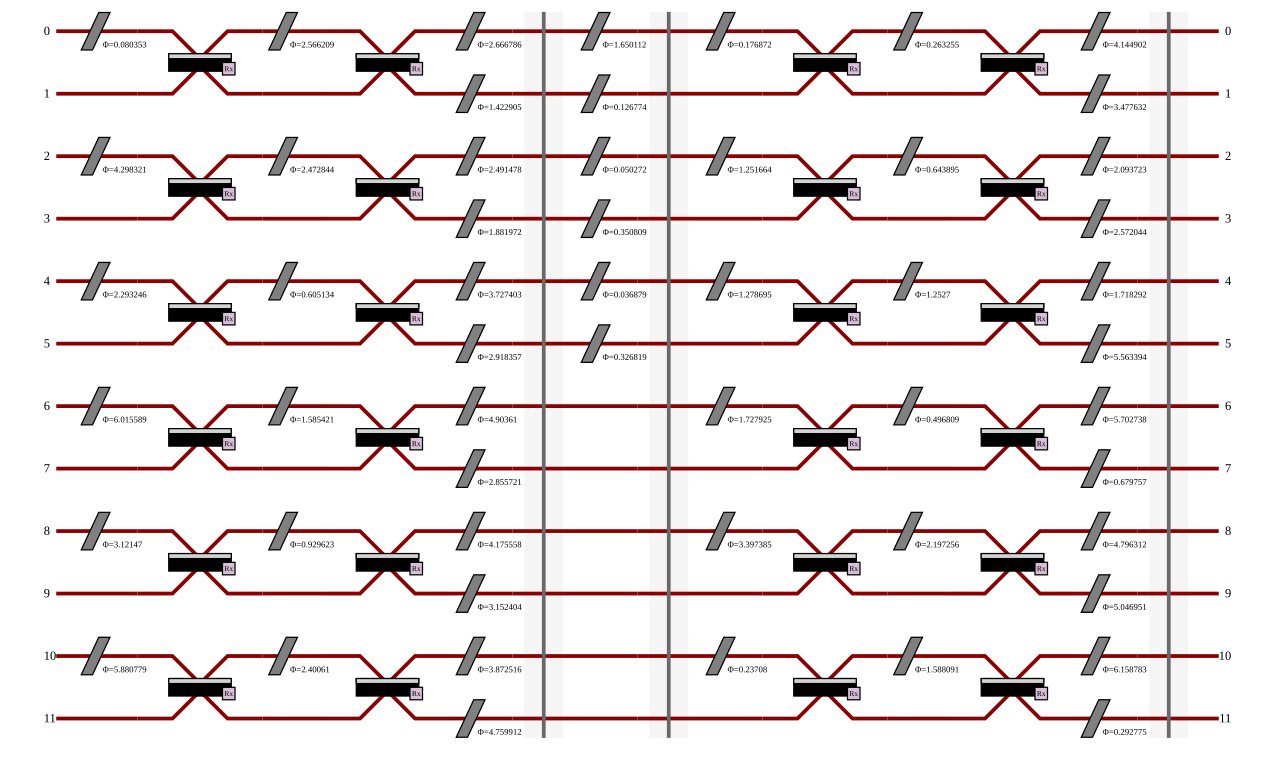

In [3]:
w = d["w6"][150]                                                           # weights at R ≈ 2.0 Å
fig = pl.draw_gate_circuit(pl.lih_gate_circuit(make_reservoir("iqm", 4, 0, cfg), w, cfg.lih_angle_map, d["w_range"]), "iqm_lih")
display(Markdown("**Euro-Q-Exa (IQM), L = 4** — `R(θ, φ)` is IQM's native PRX gate")); display(fig); plt.close(fig)
fig = pl.draw_gate_circuit(pl.lih_gate_circuit(make_reservoir("aqt", 0.5, 0, cfg), w, cfg.lih_angle_map, d["w_range"]), "aqt_lih", fold=40)
display(Markdown("**Piast-Q (AQT), ρ = 0.5**")); display(fig); plt.close(fig)
ph = make_reservoir("quandela", 1, 0, cfg)
circ = ph.full_circuit([weights_to_angles(w, cfg.lih_angle_map, d["w_range"])]); pl.draw_photonic_circuit(circ, "photonic_lih")
display(Markdown("**Lucy (Quandela), D = 1** — random mesh | 6 data phases | random mesh")); pcvl.pdisplay(circ)

**One energy-forecasting time step.** The hidden qubits start in $|+\rangle$. The two most recent inputs are uploaded one after the other, each followed by the reservoir, and then everything is measured. These are the configurations recommended in §5.

**Euro-Q-Exa (IQM), L = 1**

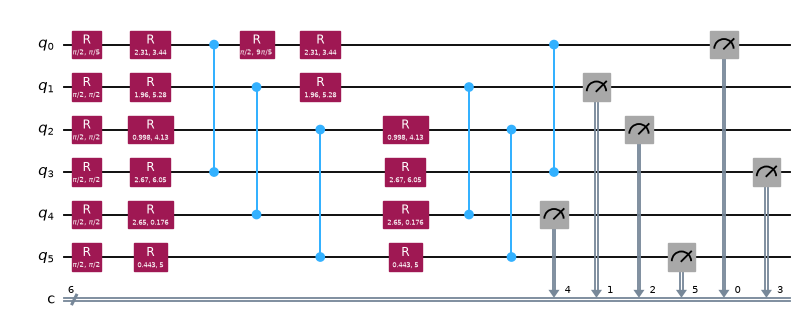

**Piast-Q (AQT), ρ = 0.5, 2 layers**

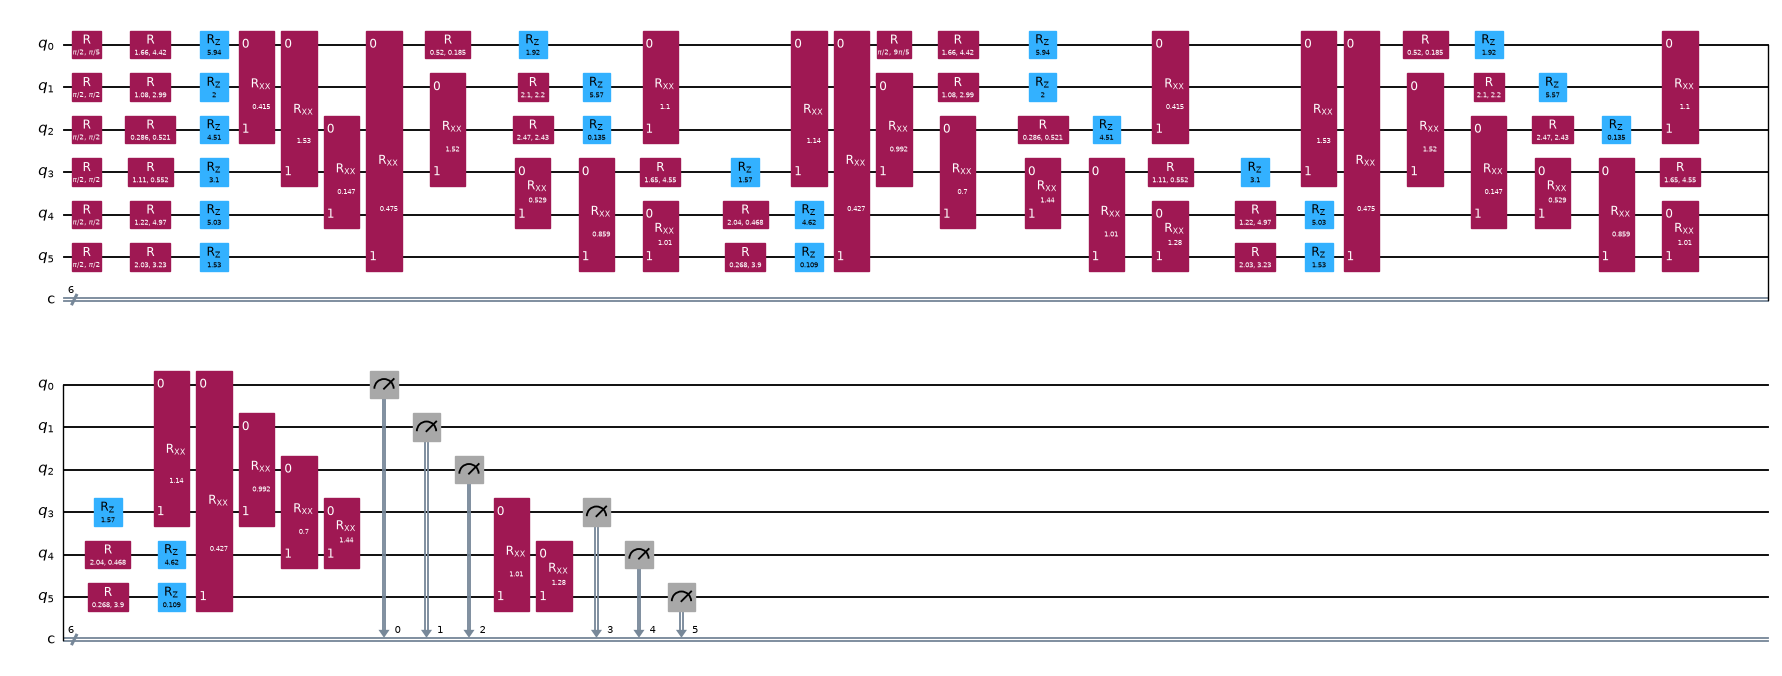

**Lucy (Quandela), D = 1** — the same interferometer after each upload

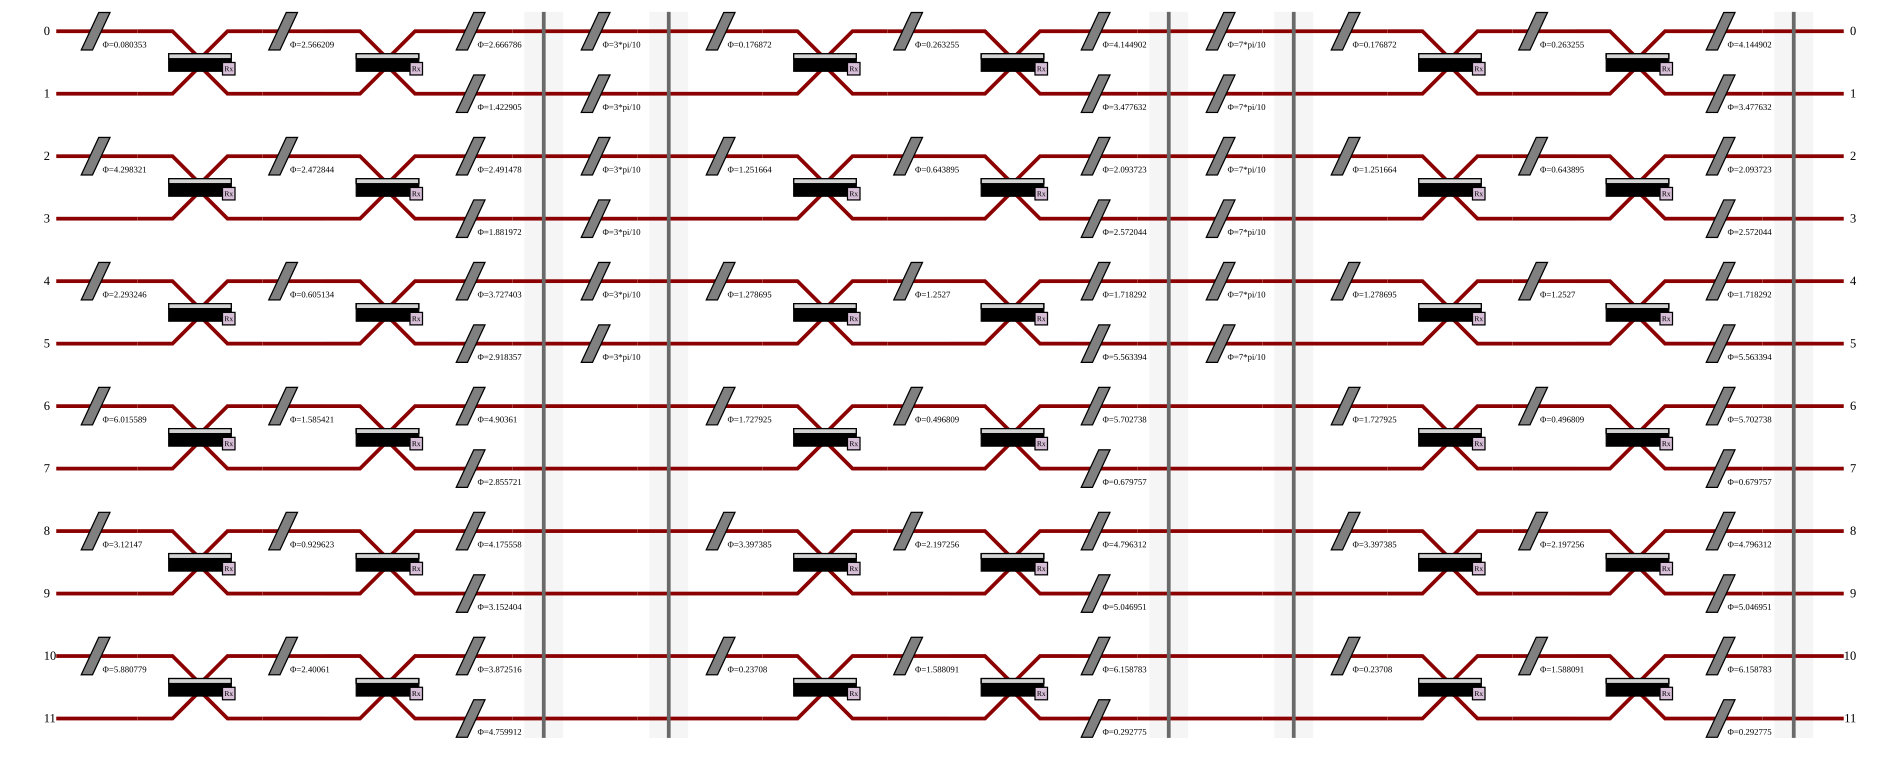

In [4]:
row = [0.3, 0.7]
fig = pl.draw_gate_circuit(GateWindowFeatures(make_reservoir("iqm", 1, 0, cfg).circuit).window_circuit(row), "iqm_qrc_step")
display(Markdown("**Euro-Q-Exa (IQM), L = 1**")); display(fig); plt.close(fig)
fig = pl.draw_gate_circuit(GateWindowFeatures(AQTIonTrapReservoir(6, density=0.5, n_layers=2, seed=700).build().circuit).window_circuit(row), "aqt_qrc_step", fold=40)
display(Markdown("**Piast-Q (AQT), ρ = 0.5, 2 layers**")); display(fig); plt.close(fig)
circ = ph.full_circuit([np.full(6, np.pi * u) for u in row]); pl.draw_photonic_circuit(circ, "photonic_qrc_step")
display(Markdown("**Lucy (Quandela), D = 1** — the same interferometer after each upload")); pcvl.pdisplay(circ)

## 2. How expressive is each reservoir?

**ORS gap (gate-based).** 
- **What it measures:** the largest output probabilities of the reservoir are compared with those of a maximally expressive (Haar-random) circuit.
- **Reading it:** a gap ≈ 0 means Haar-like, and more negative means less expressive. (A truly Haar-random 6-qubit ensemble scores ≈ +0.4 because of a finite-size bias of the reference.)
- **"± error"** is the standard error over the measurement bases.

**ORS_LO gap (photonic).** The original metric assumes random *qubit* statistics. Even a perfectly random interferometer produces photon statistics that look nothing like that, because photons bunch. ORS_LO keeps the same formula but calibrates its reference on random interferometers, so it is ≈ 0 for a Haar-random interferometer. It is **not comparable** with the gate ORS.

**$R_\mathrm{eff}$.** The effective number of independent features the readout sees. It is computed identically on every platform.

In [5]:
show(rp.ors_table(S))

platform,complexity,metric,gap ± error
Euro-Q-Exa (IQM),L = 1,ORS gap,-8.81 ± 3.90
Euro-Q-Exa (IQM),L = 2,ORS gap,-5.18 ± 1.88
Euro-Q-Exa (IQM),L = 4,ORS gap,-2.37 ± 1.17
Euro-Q-Exa (IQM),L = 8,ORS gap,0.04 ± 0.10
Euro-Q-Exa (IQM),L = 16,ORS gap,0.45 ± 0.05
Piast-Q (AQT),ρ = 0.25,ORS gap,-5.11 ± 0.21
Piast-Q (AQT),ρ = 0.5,ORS gap,-0.83 ± 0.23
Piast-Q (AQT),ρ = 0.75,ORS gap,-0.16 ± 0.18
Piast-Q (AQT),ρ = 1.0,ORS gap,0.21 ± 0.11
Lucy (Quandela),D = 1,ORS_LO gap,-182 ± 2


- **Euro-Q-Exa.** The gap closes as cycles are added: from −8.8 at $L=1$ to ≈0 at $L=8$. At $L=16$ it scores +0.45, the same as the Haar reference (+0.43).
- **Piast-Q.** Entangling more ion pairs closes the gap: from −5.1 at $\rho=0.25$ to −0.2 at $\rho=0.75$ and +0.2 at full connectivity, close to the Haar value.
- **Lucy.** The ORS_LO gap closes with mesh depth: from −182 at $D=1$ to −0.7 ± 0.6 at $D=12$. That is statistically the same as a Haar-random interferometer (−0.4 ± 0.6).

## 3. Task 1 — LiH excitation energies (QELM)

**Input: 
1. **Particle number:** two electrons, so only 10 of the 256 bitstrings ever appear.
2. **Singlet spin symmetry:** those 10 collapse to 7 configuration weights.
3. **Normalisation:** it removes one more, leaving **6 independent weights**.

Each weight becomes one native angle $\theta\in[0,\pi]$: a PRX / R gate on a qubit, or a phase shifter on Lucy. Targets, train/test split and ridge readout are Exp3's.

*Caveat:* the circuit receives numbers derived from the ground state, not the quantum state itself.

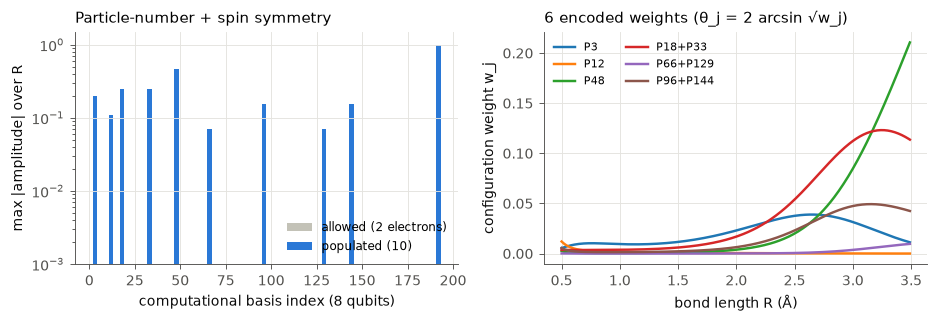

In [6]:
fig = pl.fig_lih_symmetry(d["lih"], tasks.lih_configuration_weights(d["lih"]["ground_states"])); plt.show()

**Results** (exact expectation values, 201 training geometries, 10 reservoir instances per level). Chemical accuracy is 1.6 mHa.

platform,complexity,RMSE (mHa),test points within 1.6 mHa,worst point (mHa),ORS / ORS_LO gap
Euro-Q-Exa (IQM),L = 1,0.63 ± 0.08,97%,2.44,-8.81 ± 3.90
Euro-Q-Exa (IQM),L = 2,0.47 ± 0.02,98%,1.97,-5.18 ± 1.88
Euro-Q-Exa (IQM),L = 4,0.39 ± 0.02,99%,1.70,-2.37 ± 1.17
Euro-Q-Exa (IQM),L = 8,0.36 ± 0.01,99%,1.64,0.04 ± 0.10
Euro-Q-Exa (IQM),L = 16,0.36 ± 0.02,100%,1.61,0.45 ± 0.05
Piast-Q (AQT),ρ = 0.25,0.48 ± 0.03,99%,1.98,-5.11 ± 0.21
Piast-Q (AQT),ρ = 0.5,0.36 ± 0.02,100%,1.59,-0.83 ± 0.23
Piast-Q (AQT),ρ = 0.75,0.39 ± 0.02,99%,1.71,-0.16 ± 0.18
Piast-Q (AQT),ρ = 1.0,0.41 ± 0.02,99%,1.69,0.21 ± 0.11
Lucy (Quandela),D = 1,18.97 ± 0.61,7%,67.80,-182 ± 2


**References on the same task**

model,RMSE (mHa)
"classical ridge, linear in w",4.08
"classical ridge, quadratic in w",0.49
"classical ridge, cubic in w",0.47
Exp3 Haar (full 8-qubit state),0.34
Exp3 G3_depth1000 (full 8-qubit state),0.34


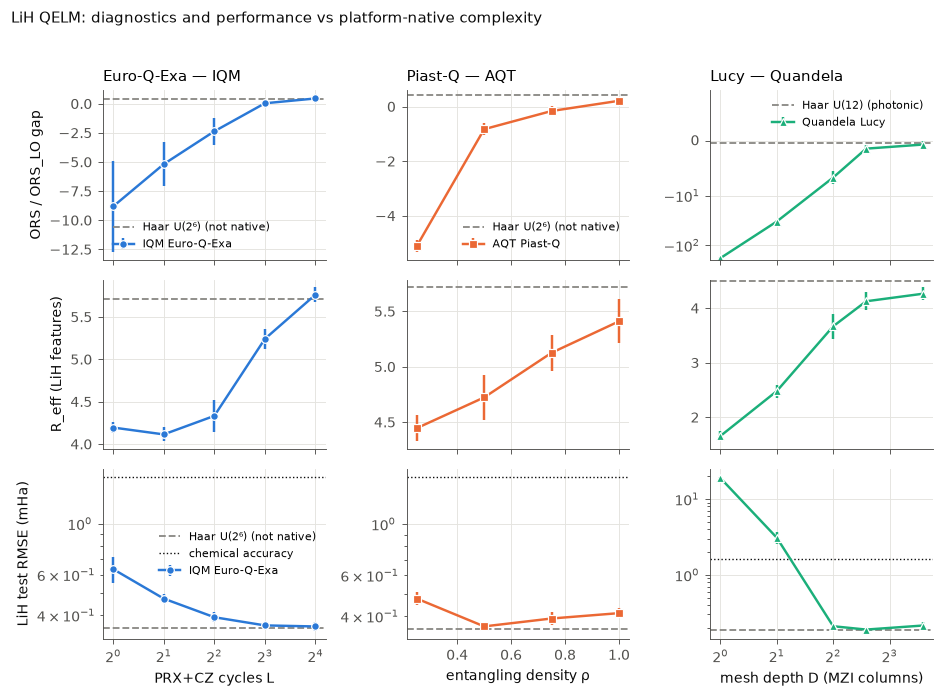

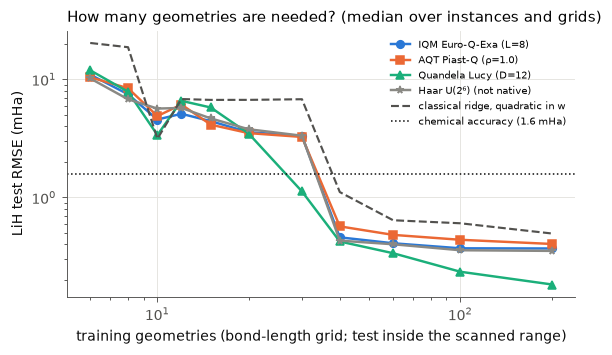

In [7]:
show(rp.lih_table(S))
exp3 = {f: 1e3 * float(np.sqrt(np.load(hs.REPO_ROOT / "results/qelm/chemistry/LiH" / f"{f}_8q_100runs.npz")["mse_all"]).mean())
        for f in ("Haar", "G3_depth1000") if (hs.REPO_ROOT / "results/qelm/chemistry/LiH" / f"{f}_8q_100runs.npz").exists()}
display(Markdown("**References on the same task**")); show(rp.lih_baselines_table(BL, exp3))
fig = pl.fig_vs_complexity(S, "lih"); plt.show()
fig = pl.fig_learning_curves(R, BL, REPRESENTATIVE, list(cfg.lih_train_sizes)); plt.show()
for t, n in ((rp.lih_table(S), "lih_results"), (rp.lih_baselines_table(BL, exp3), "lih_references")):
    pl.export_table(t, n, TAB)

- **Gate-based.** Every native level reaches chemical accuracy on average, with 97–100% of test geometries within 1.6 mHa.
  - More cycles or more entangled pairs help up to Haar-level expressivity (IQM: 0.63 → 0.36 mHa) and not beyond, as the ORS predicts.
  - At their best, both machines match Exp3's 8-qubit full-state reservoirs (0.34 mHa) using 6 qubits and native gates only.
- **Lucy.** From $D = 4$ the photonic reservoir is the most accurate model: 0.19–0.21 mHa, every test geometry within chemical accuracy.
  - Shallower meshes fail: $D = 1$ gives 19 mHa and $D = 2$ gives 3.1 mHa, because the photons barely interfere before detection.
  - ORS_LO flags exactly these two levels (gap < −30).
- **Training set** (bottom figure).
  - Under interpolation only, chemical accuracy needs about 40 training geometries on the gate-based reservoirs and 30 on Lucy.
  - The classical polynomial fits need 40 as well.
  - Below that, no model reaches it.

## 4. Task 2 — Electricity-demand forecasting (QRC)

**Data:** Exp3's ems_3 series at 15-minute resolution; this reproduces Exp3's results exactly. The task is to predict the next value from the past values.

**Memory on hardware.** Measuring a quantum state destroys it, so a QRC cannot run one long circuit and read it out at every step. Instead, **each time step runs its own circuit over the two most recent inputs** and measures everything. This needs no mid-circuit operations and runs on all three machines. For comparison:

| Protocol | Circuit per time step | Role |
|---|---|---|
| **Window 2, no reset** | upload $u_{t-1}$, reservoir, upload $u_t$, reservoir, measure all | main; executable on IQM, AQT and Lucy |
| Window 8, with reset | the same over 8 inputs, resetting the input qubit between uploads | needs mid-circuit reset (IQM, assumed) or fresh ions (AQT) |
| Continuous (Exp3) | one trajectory read out without disturbing it | idealised reference only |

platform,complexity,"window 2, no reset (executable)","window 8, reset",continuous (idealised)
Euro-Q-Exa (IQM),L = 1,0.514 ± 0.000,0.473 ± 0.007,0.415 ± 0.006
Euro-Q-Exa (IQM),L = 2,0.510 ± 0.000,0.543 ± 0.009,0.415 ± 0.003
Euro-Q-Exa (IQM),L = 4,0.510 ± 0.000,0.464 ± 0.014,0.512 ± 0.005
Euro-Q-Exa (IQM),L = 8,0.510 ± 0.000,0.502 ± 0.015,0.504 ± 0.009
Euro-Q-Exa (IQM),L = 16,0.510 ± 0.000,0.490 ± 0.013,0.530 ± 0.008
Piast-Q (AQT),ρ = 0.25,0.473 ± 0.018,0.502 ± 0.020,0.500 ± 0.018
Piast-Q (AQT),ρ = 0.5,0.510 ± 0.000,0.469 ± 0.022,0.518 ± 0.008
Piast-Q (AQT),ρ = 0.75,0.510 ± 0.000,0.488 ± 0.008,0.526 ± 0.006
Piast-Q (AQT),ρ = 1.0,0.510 ± 0.000,0.485 ± 0.009,0.526 ± 0.009
Lucy (Quandela),D = 1,-0.052 ± 0.000,—,—


**Classical models with the same readout**

classical model (same readout),test R²
persistence (ŷ_t = y_t-1),0.286
classical linear AR(2),0.445
classical linear AR(8),0.444
classical quadratic AR(2),0.492
classical quadratic AR(8),0.541


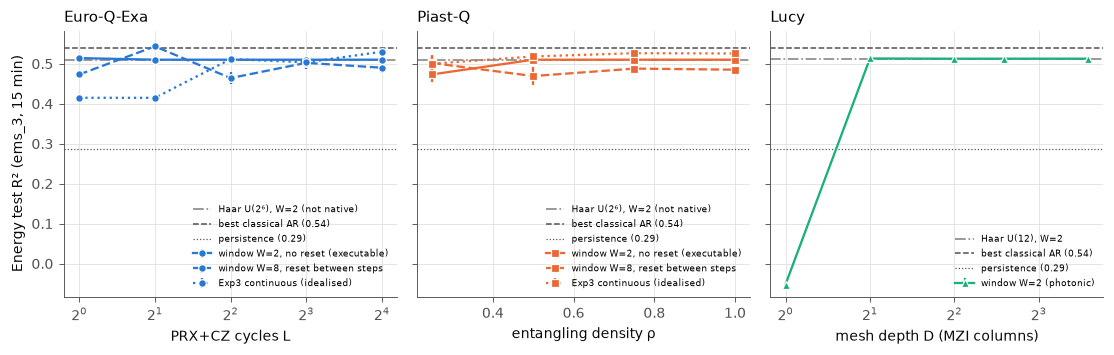

In [8]:
show(rp.qrc_table(S))
display(Markdown("**Classical models with the same readout**")); show(rp.energy_baselines_table(BE))
fig = pl.fig_qrc_protocols(S, BE); plt.show()
pl.export_table(rp.qrc_table(S), "qrc_results", TAB)

- **Window 2 (executable).** It gives the same R² on every reservoir: 0.51 on all gate levels, 0.513 on Lucy from $D=2$.
  - With only two inputs in each circuit, any sufficiently mixing reservoir gives the readout the same functions of the inputs, so the reservoir does not change the forecast.
  - The exceptions are too-sparse circuits that barely touch the input: Piast-Q at $\rho=0.25$ (0.47) and Lucy at $D=1$ (−0.05).
- **Against classical models with the same readout.** The executable protocol beats persistence (0.29) and linear forecasting (0.445). It is slightly above the quadratic model on the same two inputs (0.49) and below the quadratic model on 8 inputs (0.54).
- **Longer memory.** Reaching 0.54 needs the reset protocol (up to 0.543 on Euro-Q-Exa) and hence mid-circuit reset.
- **For hardware:** use the cheapest circuit, since expressivity buys nothing at window 2 while every extra gate adds noise.

## 5. Running it in 10–25 minutes per provider

**Training on hardware does not fit.** It would need ~10⁸ shots per platform, while 15 minutes give 10⁴–10⁷ (see below). The plan is therefore **inference only**:
1. Train the readout in simulation on a **noise-aware digital twin**: the same circuits, the vendor error model, and the *same* number of shots as on hardware.
2. Measure only the test inputs on the QPU and apply the trained readout.

A readout trained on *ideal* simulated features fails completely on noisy hardware data. Training on the twin fixes that.

**Step 1 — cheapest configuration per platform and task.** This is the cheapest native reservoir within 10% of the best LiH error, or within 0.005 of the best energy R².

In [9]:
TC = rp.recommended_table(S); show(TC); pl.export_table(TC, "tableC_recommended", TAB)
lvl = lambda s: s.split("= ")[-1]
rec = {p: TC.iloc[i] for i, p in enumerate(("iqm", "aqt", "quandela"))}
LI = cached("lih_inference", lambda: lih_inference_budget(cfg, {p: (float(lvl(r["LiH: level"])) if p == "aqt" else int(lvl(r["LiH: level"])))
                                                              for p, r in rec.items()}))
QI = cached("qrc_inference", lambda: qrc_inference_budget(cfg, [("iqm", int(lvl(rec["iqm"]["energy: level"])), None),
                                                               ("aqt", 0.5, 2),                              # 2 layers suffice (see text)
                                                               ("quandela", int(lvl(rec["quandela"]["energy: level"])), None)]))

platform,LiH: level,LiH: circuit,LiH: RMSE (mHa),energy: level,energy: circuit per time step,energy: R²
Euro-Q-Exa (IQM),L = 4,"10 two-qubit gates, depth 8, f ≈ 0.63",0.39,L = 1,"6 two-qubit gates, depth 6, f ≈ 0.67",0.514
Piast-Q (AQT),ρ = 0.5,"32 two-qubit gates, depth 27, f ≈ 0.65",0.36,ρ = 0.5,"64 two-qubit gates, depth 54, f ≈ 0.42",0.510
Lucy (Quandela),D = 6,"66 MZIs in 2 meshes + 6 data phases, 3 photons",0.19,D = 2,"66 BS, 12 data phases, 3 photons",0.513


For the energy task on Piast-Q we use 2 layers instead of 4 (32 RXX per time step, f ≈ 0.65). The window-2 forecast does not depend on the reservoir (§4), so the shorter circuit is better under noise.

**Step 2 — accuracy vs shots, inference only.**
- *LiH:* 20 test geometries measured on hardware. The gate-based machines need 3 measurement settings (X, Y, Z on every qubit); on Lucy the unit is post-selected 3-photon events. Each curve is the median over 5 reservoir instances.
- *Energy:* 200 test time steps, 1-local observables only (3 settings). This is why even the exact value is below the 0.51 of §4.
- *Reference lines:* dashed lines mark R² = 0.9 and 0.99; the dotted line is chemical accuracy.

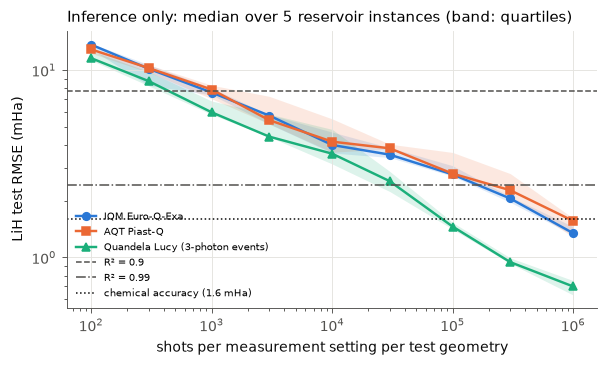

**Energy: test R² vs shots per setting per time step** (200 test steps)

shots,Piast-Q (AQT),Euro-Q-Exa (IQM),Lucy (Quandela)
30,0.026000,0.080000,-0.112000
100,0.148000,0.176000,-0.150000
300,0.269000,0.270000,0.022000
"1,000",0.345000,0.307000,0.085000
"3,000",0.343000,0.322000,0.213000
"10,000",0.412000,0.392000,0.271000
"30,000",0.396000,0.409000,0.379000
"100,000",0.412000,0.412000,0.365000
exact,0.457000,0.443000,0.438000


In [10]:
fig = pl.fig_inference_budget(LI, VAR); plt.show()
q = QI.groupby(["platform", "shots"]).test_r2.mean().unstack("platform").round(3)
q.index = ["exact" if not np.isfinite(i) else f"{int(i):,}" for i in q.index]; q.columns = [rp.NAME[c] for c in q.columns]
display(Markdown("**Energy: test R² vs shots per setting per time step** (200 test steps)")); show(q.rename_axis("shots").reset_index())

**Step 3 — what fits in 15 minutes.** Each task is assumed to get the whole window. The shot rates are **indicative figures from other systems of the same vendors, not verified**, so replace them with the providers' numbers:
- **IQM:** derived from Garnet's CLOPS.
- **AQT:** IBEX Q1's circuits per hour.
- **Lucy:** a model that reproduces Ascella's published multi-photon rates.

On the gate-based machines several 6-site reservoirs run side by side (9 on 54 qubits, 3 on 20 ions).

In [11]:
PLAN = rp.hardware_plan(LI, QI, minutes=15); show(PLAN); pl.export_table(PLAN, "hardware_plan_15min", TAB)

platform,assumed rate,budget in 15 min,LiH (20 test geometries): shots/setting,LiH: expected RMSE,energy (200 test steps): shots/setting,energy: expected R²,ORS: circuits at 10⁴ shots
Euro-Q-Exa (IQM),500 shots/s × 9 in parallel,4.0e+06,6.8e+04,≈ 3.0 mHa (R² ≈ 0.98),6.8e+03,≈ 0.37,405
Piast-Q (AQT),5.56 shots/s × 3 in parallel,1.5e+04,2.5e+02,≈ 10.7 mHa (R² ≈ 0.78),2.5e+01,< 0.03,2
Lucy (Quandela),1.37e+04 3-photon events/s,1.2e+07,6.1e+05,≈ 0.8 mHa (R² ≈ 1.00),6.1e+04,≈ 0.37,1229


- **Lucy** has by far the largest budget (≈10⁷ three-photon events).
  - It is the only machine that reaches **chemical accuracy under shot noise** (≈0.8 mHa on 20 geometries).
  - A photonic reservoir needs no gate fidelity; its limits are loss and distinguishability, which are not modelled here.
- **Euro-Q-Exa**, running 9 reservoir copies in parallel on its 54 qubits, gets LiH to R² ≈ 0.98 (≈3 mHa). Alternatively it could measure the ORS on ~400 circuits.
- **Piast-Q** is limited by the rate assumed here: 20,000 circuits per hour, each counted as a single shot. That is deliberately conservative.
  - At this rate a reduced test fits: 5 geometries at 10³ shots gives R² ≈ 0.88.
  - If AQT's figure means circuits of ~100 shots, Piast-Q's budget approaches Euro-Q-Exa's.
- **Energy under shot noise** drops to R² ≈ 0.37 on Euro-Q-Exa and Lucy (and near 0 on Piast-Q at the assumed rate), below linear forecasting. So the hardware run shows that the protocol executes and that the noise-aware twin predicts hardware results; it does not show a forecasting advantage.
- **Recommended allocation:**
  - LiH inference as the main experiment on every machine;
  - one energy configuration as an executability demonstration;
  - on Euro-Q-Exa, ORS measurements on the parallel patches.

## 6. Noisy simulations

Three checks with realistic noise, using the vendors' own tools where they exist:
1. **The vendor tools accept the circuits.** The IQM and AQT SDKs need an older qiskit, so they run in a separate environment (`../.venv-vendor`) and exchange only JSON with this code. The exported circuits, including one complete energy-forecasting time step per level, are transpiled for IQM's Crystal-54 chip and for AQT's API.
2. **Expressivity under noise:** the ORS measured on the vendors' noisy emulators.
3. **Task performance under noise:** the LiH and energy tasks, run on the vendors' noisy emulators (IQM, AQT) and with Perceval's noise model (Lucy).

In [12]:
vpath = OUT / "vendor" / "circuits.json"
if FORCE or not vpath.exists():
    export_vendor_circuits(cfg, n_instances=5)
if VENDOR_PY.exists() and (FORCE or not (OUT / "vendor" / "validation.json").exists()):
    subprocess.run([str(VENDOR_PY), "experiments/native_hardware/vendor_validate.py", "--circuits", str(vpath)], capture_output=True)
show(rp.vendor_summary(json.loads((OUT / "vendor" / "validation.json").read_text())))
NX = vendor_noise_crosscheck(cfg)
nx = NX.groupby(["platform", "level"])[["f_est", "ors_gap_ideal", "ors_gap_emulator_f1", "ors_gap_emulator_fest"]].mean().round(2).reset_index()
nx.columns = ["platform", "level", "fidelity estimate", "ORS gap (ideal)", "ORS gap (noisy emulator, raw)", "ORS gap (noisy emulator, corrected)"]
display(Markdown("**ORS from the vendors' noisy emulators** (Z basis)")); show(nx)

platform,kind,circuits,passed,swaps
Piast-Q (AQT),full QRC time step (window 2),4,4,0
Piast-Q (AQT),reservoir circuits,20,20,0
Euro-Q-Exa (IQM),full QRC time step (window 2),5,5,0
Euro-Q-Exa (IQM),reservoir circuits,25,25,0


**ORS from the vendors' noisy emulators** (Z basis)

platform,level,fidelity estimate,ORS gap (ideal),"ORS gap (noisy emulator, raw)","ORS gap (noisy emulator, corrected)"
aqt,0.25,0.800000,-4.830000,-3.440000,-6.920000
aqt,0.5,0.650000,0.490000,-0.350000,0.520000
aqt,0.75,0.560000,-0.490000,-0.230000,-2.010000
aqt,1.0,0.450000,0.850000,-2.040000,-0.160000
iqm,1,0.700000,-29.140000,-20.220000,-34.410000
iqm,16,0.410000,0.570000,-12.230000,-0.460000
iqm,2,0.680000,-13.260000,-7.260000,-16.600000
iqm,4,0.630000,-6.550000,-1.390000,-8.000000
iqm,8,0.550000,-1.220000,-0.570000,-0.540000


- **All exported circuits pass:** 0 SWAPs on IQM, native gates only, and AQT's API accepts them (including its measure-at-the-end rule).
- **Noise and the ORS:** noise shifts the raw ORS, and the repository's existing noise-corrected ORS, as used for the IBM hardware runs, largely removes that shift. It is ready for real Euro-Q-Exa / Piast-Q data.

### Task performance under realistic noise

Every task input is "measured" on a noisy emulator with 10⁴ shots per setting:
- **Euro-Q-Exa:** IQM's fake Crystal-54 backend, which carries the SDK's sample noise model.
- **Piast-Q:** AQT's noisy offline simulator.
- **Lucy:** Perceval's noise model with Ascella's published source figures, the closest verified numbers: indistinguishability 0.94, multi-photon emission g2 = 0.007, and 8% transmission.

Per machine this is 300 LiH geometries and about 5,000 energy time steps, each measured in 3 settings (X, Y or Z on every qubit). On Lucy the unit is post-selected 3-photon events. The configurations are those of §5.

The columns go from ideal to fully noisy:
- *noise-free* — exact features. They use 1-local observables only, which is why these values sit slightly below §3–4.
- *twin prediction* — what §5 predicts: the digital twin (one global fidelity f plus shot noise; ideal photons plus shot noise on Lucy), trained and tested on itself.
- *emulator: twin readout* — the inference-only plan of §5: readout trained on the twin, test inputs measured on the emulator.
- *emulator: calibrated twin* — the same, except that the twin's noise parameters are first fitted to the measured test features against their simulated values. This uses no energies and no extra circuits:
  - gate-based machines: one scale and offset per feature;
  - Lucy: one weight between ideal and fully distinguishable photons.
- *emulator: trained on emulator* — reference only: the training data also come from the emulator, which would not fit in 15 minutes of QPU time.

Test sets are the full ones: 99 geometries and 750 time steps. Values with ± are the mean and spread over 3 shot-noise draws.

In [13]:
from native_reservoirs import noisy_emulation as ne
NOISY_CONF = {"lih": {p: (float(lvl(r["LiH: level"])) if p == "aqt" else int(lvl(r["LiH: level"])), None) for p, r in rec.items()},
              "energy": {"iqm": (int(lvl(rec["iqm"]["energy: level"])), None), "aqt": (0.5, 2),     # as in §5
                         "quandela": (int(lvl(rec["quandela"]["energy: level"])), None)}}
tpath = OUT / "vendor" / "task_circuits.json"
if FORCE or not tpath.exists():
    ne.export_task_circuits(cfg, NOISY_CONF)
missing = [(p, t) for t in NOISY_CONF for p in ("iqm", "aqt") if not ne.counts_path(cfg, p, t).exists()]
if VENDOR_PY.exists() and (FORCE or missing):                      # ~10 min on the vendor emulators
    subprocess.run([str(VENDOR_PY), "experiments/native_hardware/vendor_tasks.py", "--tasks", str(tpath)], capture_output=True)
NT = cached("noisy_task_performance", lambda: ne.noisy_task_performance(cfg, NOISY_CONF))
TN = rp.noisy_task_table(NT); pl.export_table(TN, "noisy_task_performance", TAB)
display(Markdown(f"**Task performance under realistic noise** ({ne.SHOTS:,} shots per setting / photon events per input)")); show(TN)

**Task performance under realistic noise** (10,000 shots per setting / photon events per input)

platform,task,configuration,noise-free,twin prediction,emulator: twin readout,emulator: calibrated twin,emulator: trained on emulator
Euro-Q-Exa (IQM),LiH RMSE,L = 4,0.60 mHa,3.21 ± 0.12 mHa,11.50 ± 0.09 mHa,3.15 ± 0.11 mHa,3.05 mHa
Piast-Q (AQT),LiH RMSE,ρ = 0.5,0.31 mHa,5.22 ± 0.17 mHa,7.00 ± 0.37 mHa,4.71 ± 0.14 mHa,4.34 mHa
Lucy (Quandela),LiH RMSE,D = 6,0.21 mHa,3.39 ± 0.27 mHa,4.18 ± 0.32 mHa,3.76 ± 0.22 mHa,3.73 ± 0.33 mHa
Euro-Q-Exa (IQM),energy R²,L = 1,0.490,0.448 ± 0.006,0.329 ± 0.028,0.454 ± 0.006,0.450
Piast-Q (AQT),energy R²,"ρ = 0.5, 2 layers",0.493,0.466 ± 0.010,0.403 ± 0.046,0.481 ± 0.005,0.472
Lucy (Quandela),energy R²,D = 2,0.510,0.379 ± 0.009,0.288 ± 0.087,0.353 ± 0.005,0.360 ± 0.017


- **The uncalibrated twin fails on Euro-Q-Exa:** LiH 11.5 mHa instead of the predicted 3.2 mHa, and energy R² 0.33 instead of 0.45.
  - In the LiH circuits, the emulator damps each feature by 0.73–0.85, depending on the qubit and basis. The twin assumes one global factor of 0.63.
  - A readout trained on the wrongly scaled features is therefore biased on the device.
  - Piast-Q and Lucy lose less, but for the same reason.
- **Calibrating the twin on the measured test data fixes it on every machine.** Inference only then comes within about 10% of a readout trained on the emulator itself:

  | Machine | LiH | Energy R² |
  |---|---|---|
  | Euro-Q-Exa | 3.2 vs 3.1 mHa | 0.454 vs 0.450 |
  | Piast-Q | 4.7 vs 4.3 mHa | 0.481 vs 0.472 |
  | Lucy | 3.8 vs 3.7 mHa | 0.35 vs 0.36 |

- **The twin's own prediction (second column) matches the calibrated results to within about 10%.** It is slightly pessimistic on Piast-Q and slightly optimistic on Lucy, so the §5 shot budgets stay valid.
- **For the hardware plan:** add this calibration step to §5. It costs no QPU time, since it only uses the test circuits that are measured anyway.
- **Noise and the energy task:** the energy task keeps R² ≈ 0.45–0.48 on the gate-based emulators, just above linear forecasting (0.445). Lucy's 10⁴ events give 0.35.

### Lucy: how much photon distinguishability can the reservoir tolerate?

Partial distinguishability is the main photonic noise source. This sweep varies the photon indistinguishability, keeping g2 and loss at Ascella's values and 10⁴ events per input. The grey band marks Ascella's 0.94.

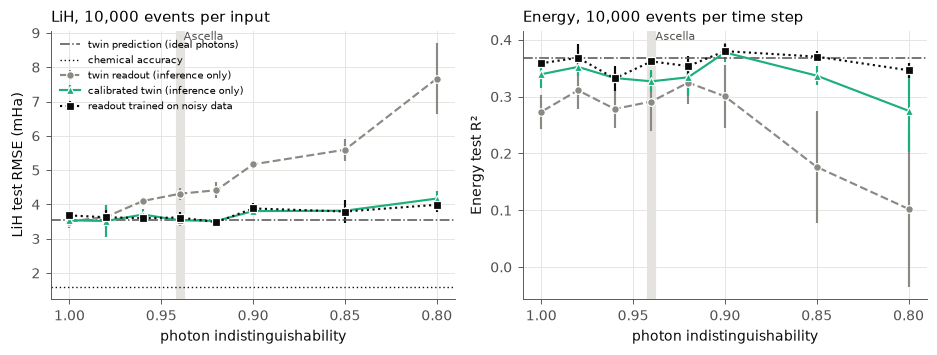

In [14]:
PS = cached("perceval_noise_sweep", lambda: ne.perceval_noise_sweep(cfg, NOISY_CONF))
fig = pl.fig_perceval_noise(PS); plt.show()

- **Uncalibrated twin readout.** It degrades steadily as photons become distinguishable: LiH goes from 3.5 to 7.7 mHa and energy R² from 0.27 to 0.10 between indistinguishability 1.0 and 0.8.
- **Calibrated twin.** It stays close to a readout trained on the noisy data: within 0.2 mHa for LiH over the whole range, and within 0.04 in R² for energy down to 0.85.
- **Why it works:** to a good approximation, partial distinguishability blends the ideal output with the classical, distinguishable-photon output, and one fitted weight captures that.
- **At Ascella's level (0.94),** photon noise costs Lucy little once the twin is calibrated. Its measured source figures should replace Ascella's at access time.

## 7. Summary figures and table for the proposal

- **Fig. 1:** diagnostics vs performance. The gate-based ORS and the photonic ORS_LO are in separate panels because they are different metrics.
- **Fig. 2:** $R_\mathrm{eff}$ vs performance.
- **Fig. 3:** performance vs native complexity, shown in §3 and §4.
- **Table B:** representative resources and results.

Faint dots are single reservoir instances; large markers are means ± standard error.

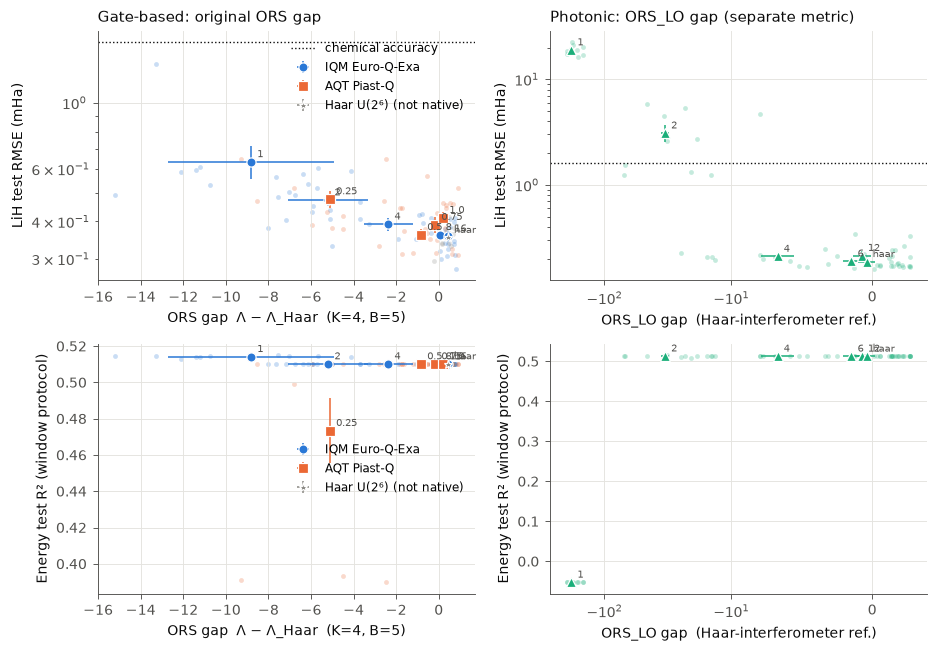

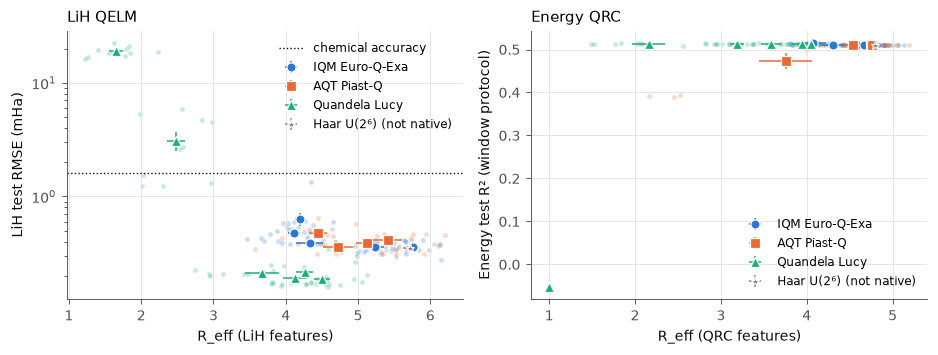

**Table B — representative resources and results**

platform,level,sites,depth (modality-specific),1Q | BS,2Q | PS,routing / density / patterns,f_est,ORS gap (Lucy: ORS_LO),R_eff LiH,LiH RMSE (mHa),R_eff QRC,energy R² (W=2),QRC circuit per time step
Euro-Q-Exa,L=8,6 qubits,16 (2Q depth 8),48,19,0 SWAPs,0.55,0.04 ± 0.10,5.24 ± 0.12,0.36 ± 0.01,4.7 ± 0.0,0.510 ± 0.000,"W=2: depth 34, 38 2Q, 18 settings, f≈0.41"
Piast-Q,ρ=1.0,6 qubits,35 (2Q depth 27),48 (24 virtual),60,ρ=1.00,0.45,0.21 ± 0.11,5.41 ± 0.20,0.41 ± 0.02,4.8 ± 0.0,0.510 ± 0.000,"W=2: depth 68, 120 2Q, 18 settings, f≈0.20"
Lucy,D=12,3 photons / 12 modes,25 optical layers,264 BS,294 PS (6 data),364 photon patterns,—,-0.74 ± 0.63,4.26 ± 0.12,0.21 ± 0.02,3.9 ± 0.1,0.513 ± 0.000,"396 BS, 12 data phases (W=2)"
Haar reference,Haar U(2⁶),6 qubits,—,—,—,not native,—,0.43 ± 0.04,5.72 ± 0.09,0.35 ± 0.01,4.8 ± 0.1,0.510 ± 0.000,—


In [15]:
fig = pl.fig_ors_vs_performance(S, R); plt.show()
fig = pl.fig_reff_vs_performance(S, R); plt.show()
TB = pl.table_resources_results(S, REPRESENTATIVE); pl.export_table(TB, "tableB_resources_results", TAB)
display(Markdown("**Table B — representative resources and results**")); show(TB)

## 8. Limitations and assumptions

- **Scale.** Each reservoir has 6 encoding sites (6 qubits, or 6 data phases on Lucy). Behaviour at hardware scale is not yet measured.
- **Noise models.** They are reference models, not calibrations of the three machines:
  - Euro-Q-Exa: IQM's sample error profile;
  - Piast-Q: AQT's published figures;
  - Lucy: ideal photons in §3–5; Ascella's published source figures in §6, standing in for Lucy's.
- **LiH input.** The circuit receives six numbers computed from the ground state, not the quantum state itself.
- **Energy task.** At the executable window, the reservoir does not change the forecast, and the QRC does not beat the best classical model.
- **Unverified assumptions.** These must be confirmed with the providers; the full list is in `native_reservoirs/hardware_specs.py`:
  - all shot rates;
  - Lucy running 3 photons, its coincidence rate, number-resolving detectors and selectable input modes;
  - the actual Euro-Q-Exa chip map;
  - mid-circuit reset on Euro-Q-Exa, needed only for the window-8 protocol.
- **Modality-specific metrics.** ORS_LO, optical depth and component counts are never compared numerically with gate-based quantities.

### From feasibility prototype to EuroHPC hardware

This prototype demonstrates the **complete workflow at emulator-accessible scale** on all three EuroHPC machines:

**native reservoir design → native resource metrics → ORS / ORS_LO / $R_\mathrm{eff}$ → QELM (LiH) and QRC (energy) performance.**

It also comes with a concrete **inference-only plan** that fits the available QPU time.

EuroHPC QPU access will be used to:
1. **Scale the reservoirs toward the physical hardware capacity:**
   - Euro-Q-Exa: up to 54 qubits (and the 150-qubit system), where many reservoirs also run in parallel.
   - Piast-Q: up to 20 ions.
   - Lucy: more photons and modes as the rates allow.

   Measuring the ORS at these sizes, where classical simulation becomes hard, is where hardware adds the most.
2. **Measure real hardware noise and calibration effects:** gate and readout errors, drift, photon loss and distinguishability. These replace the error models used for the noise-aware twin.
3. **Compare physical execution against ideal and noise-aware simulations:** hardware counts go through the noise-corrected ORS already used for IBM hardware and are compared with the twin's predictions.
4. **Quantify operational performance on the real QPUs:** LiH error and energy R² at the achievable shot counts, real shot rates, and whether ORS and $R_\mathrm{eff}$ still predict performance on hardware.